In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
import os

for root, dirs, files in os.walk("/"):
    if "diabetic_data.csv" in files:
        print("File found at:", os.path.join(root, "diabetic_data.csv"))


File found at: /content/drive/MyDrive/Machine learing project/diabetes+130-us+hospitals+for+years+1999-2008/diabetic_data.csv


In [ ]:
dataset_path = "/content/drive/MyDrive/Machine learing project/diabetes+130-us+hospitals+for+years+1999-2008/diabetic_data.csv"

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (101766, 50)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [ ]:
print(df["readmitted"].value_counts())

print("\nReadmission percentages:")
print(
    df["readmitted"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Readmission percentages:
readmitted
NO     53.91
>30    34.93
<30    11.16
Name: proportion, dtype: float64


In [ ]:
print("Missing values per column:")
print(df.isna().sum().sort_values(ascending=False).head(15))

print("\nQuestion mark values:")
print((df == "?").sum().sort_values(ascending=False).head(15))


Missing values per column:
max_glu_serum               96420
A1Cresult                   84748
race                            0
gender                          0
age                             0
weight                          0
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                      0
medical_specialty               0
num_lab_procedures              0
num_procedures                  0
num_medications                 0
dtype: int64

Question mark values:
weight                 98569
medical_specialty      49949
payer_code             40256
race                    2273
diag_3                  1423
diag_2                   358
diag_1                    21
admission_type_id          0
patient_nbr                0
encounter_id               0
time_in_hospital           0
admission_source_id        0
num_lab_procedures         0
num_procedures             0
num_medications      

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    if 'diabetic_data.csv' in files:
        print("Dataset:", os.path.join(root, 'diabetic_data.csv'))

Dataset: /content/drive/MyDrive/Machine learing project/diabetes+130-us+hospitals+for+years+1999-2008/diabetic_data.csv


In [ ]:
import pandas as pd
import os

dataset_path = "/content/drive/MyDrive/Machine learing project/diabetes+130-us+hospitals+for+years+1999-2008/diabetic_data.csv"

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (101766, 50)


In [ ]:
print(df["readmitted"].value_counts())

print("\nPercentage:")
print(
    df["readmitted"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Percentage:
readmitted
NO     53.91
>30    34.93
<30    11.16
Name: proportion, dtype: float64


In [ ]:
import seaborn as sns

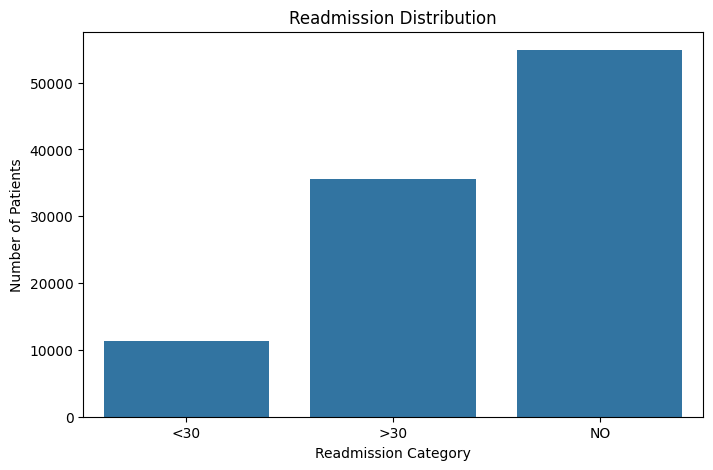

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="readmitted",
    order=["<30", ">30", "NO"]
)

plt.title("Readmission Distribution")
plt.xlabel("Readmission Category")
plt.ylabel("Number of Patients")
plt.show()

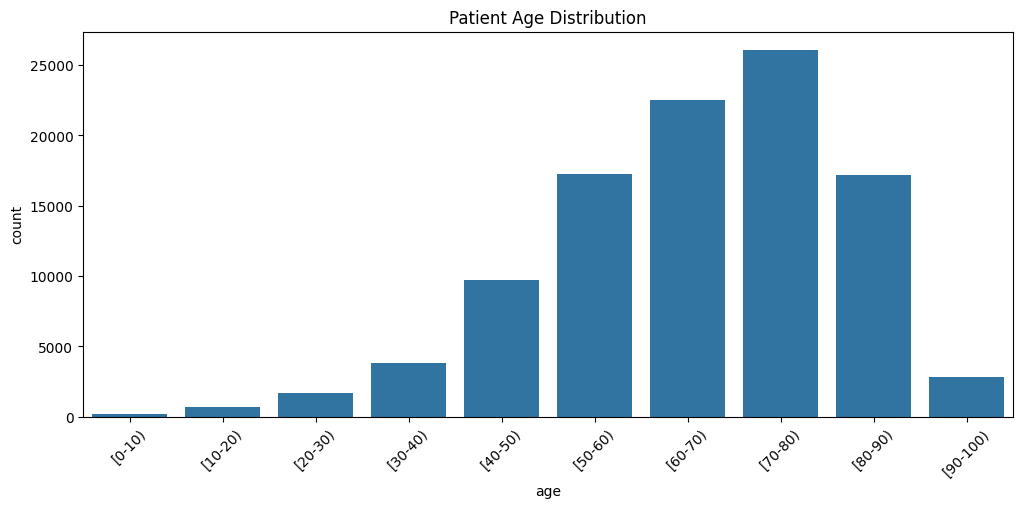

In [ ]:
plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x="age",
    order=sorted(df["age"].unique())
)

plt.title("Patient Age Distribution")
plt.xticks(rotation=45)
plt.show()

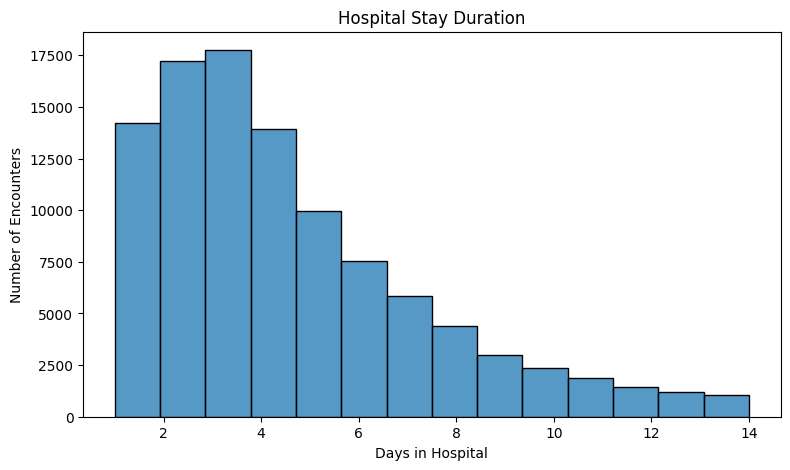

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="time_in_hospital",
    bins=14
)

plt.title("Hospital Stay Duration")
plt.xlabel("Days in Hospital")
plt.ylabel("Number of Encounters")
plt.show()

In [ ]:
visit_columns = [
    "number_outpatient",
    "number_emergency",
    "number_inpatient"
]

print(df[visit_columns].describe())

       number_outpatient  number_emergency  number_inpatient
count      101766.000000     101766.000000     101766.000000
mean            0.369357          0.197836          0.635566
std             1.267265          0.930472          1.262863
min             0.000000          0.000000          0.000000
25%             0.000000          0.000000          0.000000
50%             0.000000          0.000000          0.000000
75%             0.000000          0.000000          1.000000
max            42.000000         76.000000         21.000000


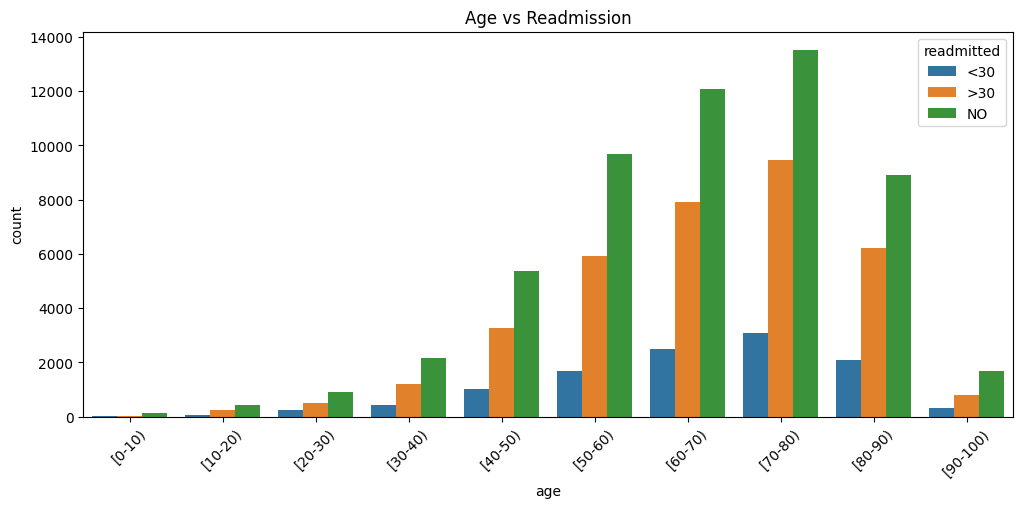

In [ ]:
plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x="age",
    hue="readmitted",
    hue_order=["<30", ">30", "NO"]
)

plt.title("Age vs Readmission")
plt.xticks(rotation=45)
plt.show()

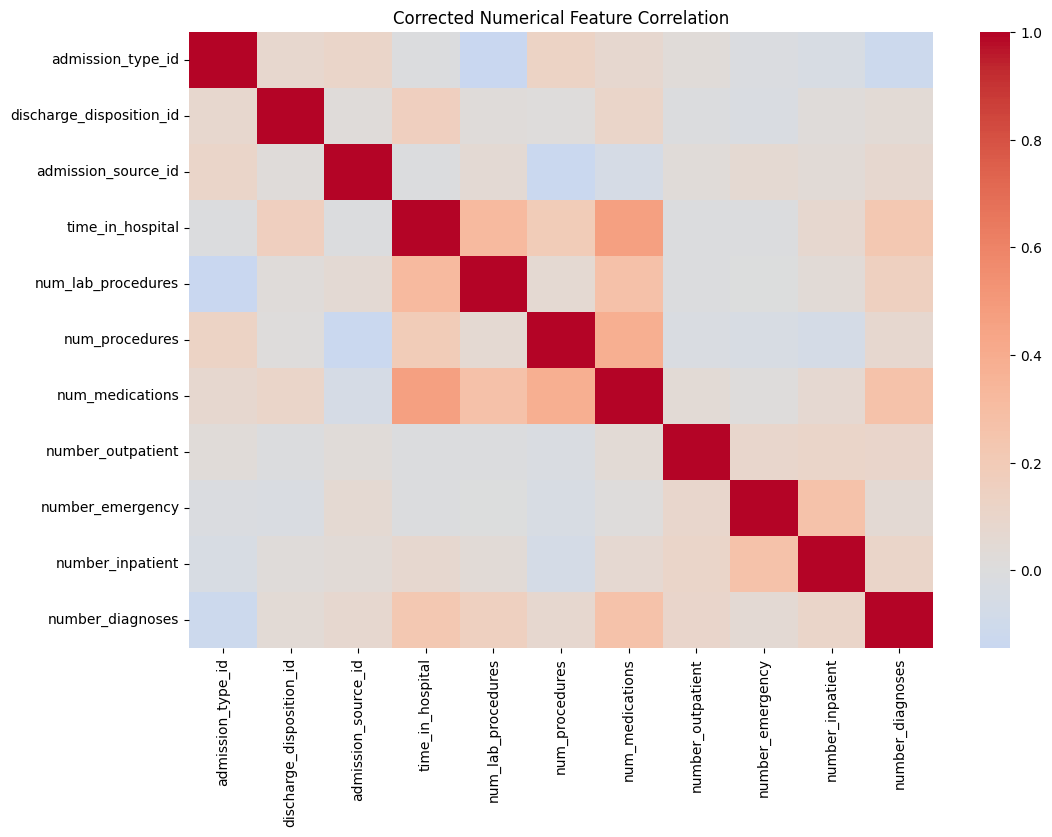

In [ ]:
exclude_columns = [
    "encounter_id",
    "patient_nbr"
]

numeric_df = df.select_dtypes(
    include="number"
).drop(columns=exclude_columns, errors="ignore")

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Corrected Numerical Feature Correlation")

plt.show()

In [ ]:
import os

os.makedirs("results", exist_ok=True)

df["readmitted"].value_counts().to_csv(
    "results/readmission_distribution.csv"
)

print("EDA results saved!")

EDA results saved!


In [ ]:
age_readmission = pd.crosstab(
    df["age"],
    df["readmitted"],
    normalize="index"
) * 100

print(age_readmission.round(2))

readmitted    <30    >30     NO
age                            
[0-10)       1.86  16.15  81.99
[10-20)      5.79  32.42  61.79
[20-30)     14.24  30.78  54.98
[30-40)     11.23  31.44  57.32
[40-50)     10.60  33.85  55.55
[50-60)      9.67  34.29  56.04
[60-70)     11.13  35.12  53.75
[70-80)     11.77  36.35  51.88
[80-90)     12.08  36.19  51.73
[90-100)    11.10  28.93  59.97


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

dataset_path = "/content/drive/MyDrive/Machine learing project/diabetes+130-us+hospitals+for+years+1999-2008/diabetic_data.csv"

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset loaded successfully!
Dataset Shape: (101766, 50)


In [ ]:
df["readmitted_30"] = df["readmitted"].map({
    "<30": 1,
    ">30": 0,
    "NO": 0
})

print(df[["readmitted", "readmitted_30"]].head(10))

  readmitted  readmitted_30
0         NO              0
1        >30              0
2         NO              0
3         NO              0
4         NO              0
5        >30              0
6         NO              0
7        >30              0
8         NO              0
9         NO              0


In [ ]:
print(df["readmitted_30"].value_counts(dropna=False))

readmitted_30
0    90409
1    11357
Name: count, dtype: int64


In [ ]:
assert df["readmitted_30"].notna().all()

print("Target creation successful!")

Target creation successful!


In [ ]:
target_counts = df["readmitted_30"].value_counts()

target_percentage = (
    df["readmitted_30"]
    .value_counts(normalize=True) * 100
)

print("Class Counts:")
print(target_counts)

print("\nClass Percentages:")
print(target_percentage.round(2))

Class Counts:
readmitted_30
0    90409
1    11357
Name: count, dtype: int64

Class Percentages:
readmitted_30
0    88.84
1    11.16
Name: proportion, dtype: float64


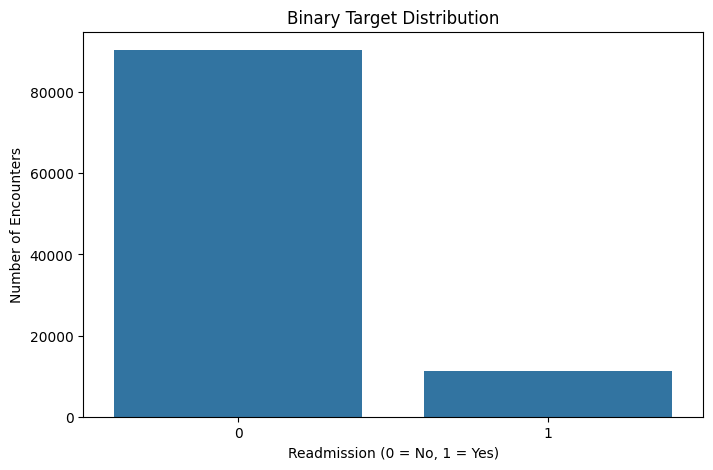

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="readmitted_30"
)

plt.title("Binary Target Distribution")
plt.xlabel("Readmission (0 = No, 1 = Yes)")
plt.ylabel("Number of Encounters")

plt.show()

In [ ]:
# Target variable
y = df["readmitted_30"]

# Patient ID and encounter ID are identifiers, not predictive features
X = df.drop(
    columns=[
        "readmitted",
        "readmitted_30",
        "encounter_id",
        "patient_nbr"
    ]
)

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (101766, 47)
Target Shape: (101766,)


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

groups = df["patient_nbr"]

In [ ]:
gss_test = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_val_idx, test_idx = next(
    gss_test.split(X, y, groups=groups)
)

In [ ]:
gss_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_rel_idx, val_rel_idx = next(
    gss_val.split(
        X.iloc[train_val_idx],
        y.iloc[train_val_idx],
        groups=groups.iloc[train_val_idx]
    )
)

train_idx = train_val_idx[train_rel_idx]
val_idx = train_val_idx[val_rel_idx]

In [ ]:
X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_val = y.iloc[val_idx].copy()
y_test = y.iloc[test_idx].copy()

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (65146, 47)
Validation: (16467, 47)
Testing: (20153, 47)


In [ ]:
train_patients = set(groups.iloc[train_idx])
val_patients = set(groups.iloc[val_idx])
test_patients = set(groups.iloc[test_idx])

print("Train-Val Overlap:",
      len(train_patients & val_patients))

print("Train-Test Overlap:",
      len(train_patients & test_patients))

print("Val-Test Overlap:",
      len(val_patients & test_patients))

Train-Val Overlap: 0
Train-Test Overlap: 0
Val-Test Overlap: 0


In [ ]:
print("Training Class Distribution:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nValidation Class Distribution:")
print((y_val.value_counts(normalize=True) * 100).round(2))

print("\nTesting Class Distribution:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training Class Distribution:
readmitted_30
0    88.75
1    11.25
Name: proportion, dtype: float64

Validation Class Distribution:
readmitted_30
0    88.6
1    11.4
Name: proportion, dtype: float64

Testing Class Distribution:
readmitted_30
0    89.33
1    10.67
Name: proportion, dtype: float64


In [ ]:
import os

PROJECT_PATH = "/content/drive/MyDrive/Machine learing project"

folders = [
    "processed_data",
    "models",
    "results",
    "notebooks",
    "reports",
    "presentation"
]

for folder in folders:
    os.makedirs(
        os.path.join(PROJECT_PATH, folder),
        exist_ok=True
    )

print("Project folders created successfully!")

Project folders created successfully!


In [ ]:
print("splits exists:", "splits" in globals())

print("Available split variables:")

for name in globals():
    if "split" in name.lower():
        print(name)

splits exists: False
Available split variables:
GroupShuffleSplit


In [ ]:
for name in globals():
    if any(word in name.lower() for word in ["train", "test", "val", "split"]):
        print(name)

GroupShuffleSplit
gss_test
train_val_idx
test_idx
gss_val
train_rel_idx
val_rel_idx
train_idx
val_idx
X_train
X_val
X_test
y_train
y_val
y_test
train_patients
val_patients
test_patients


In [ ]:
splits = {
    "X_train": X_train,
    "X_val": X_val,
    "X_test": X_test,
    "y_train": y_train,
    "y_val": y_val,
    "y_test": y_test,
    "train_idx": train_idx,
    "val_idx": val_idx,
    "test_idx": test_idx
}

print("Splits dictionary created successfully!")

for name, data in splits.items():
    print(name, data.shape)

Splits dictionary created successfully!
X_train (65146, 47)
X_val (16467, 47)
X_test (20153, 47)
y_train (65146,)
y_val (16467,)
y_test (20153,)
train_idx (65146,)
val_idx (16467,)
test_idx (20153,)


In [ ]:
import os
import joblib

save_path = os.path.join(
    PROJECT_PATH,
    "processed_data",
    "day3_splits.joblib"
)

joblib.dump(splits, save_path)

print("Day 3 datasets saved successfully!")
print("Saved location:", save_path)

Day 3 datasets saved successfully!
Saved location: /content/drive/MyDrive/Machine learing project/processed_data/day3_splits.joblib


In [ ]:
print("File exists:", os.path.exists(save_path))

print(
    "File size:",
    round(os.path.getsize(save_path) / (1024 * 1024), 2),
    "MB"
)

File exists: True
File size: 29.83 MB


In [ ]:
import joblib

loaded_splits = joblib.load(save_path)

print("Saved splits loaded successfully!")

for name, data in loaded_splits.items():
    print(name, data.shape)

Saved splits loaded successfully!
X_train (65146, 47)
X_val (16467, 47)
X_test (20153, 47)
y_train (65146,)
y_val (16467,)
y_test (20153,)
train_idx (65146,)
val_idx (16467,)
test_idx (20153,)


In [ ]:
import os

print("File exists:", os.path.exists(save_path))
print("File size:", round(os.path.getsize(save_path) / (1024 * 1024), 2), "MB")

File exists: True
File size: 29.83 MB


In [ ]:
PROJECT_PATH = "/content/drive/MyDrive/Machine learing project"

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

PROJECT_PATH = "/content/drive/MyDrive/Machine learing project"

dataset_path = os.path.join(
    PROJECT_PATH,
    "diabetes+130-us+hospitals+for+years+1999-2008",
    "diabetic_data.csv"
)

df = pd.read_csv(dataset_path)

print("Original dataset:", df.shape)

Original dataset: (101766, 50)


In [ ]:
split_path = os.path.join(
    PROJECT_PATH,
    "processed_data",
    "day3_splits.joblib"
)

splits = joblib.load(split_path)

X_train = splits["X_train"]
X_val = splits["X_val"]
X_test = splits["X_test"]

y_train = splits["y_train"]
y_val = splits["y_val"]
y_test = splits["y_test"]

print("Day 3 data loaded successfully!")


Day 3 data loaded successfully!


In [ ]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nTarget shapes:")

print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)


Training: (65146, 47)
Validation: (16467, 47)
Testing: (20153, 47)

Target shapes:
y_train: (65146,)
y_val: (16467,)
y_test: (20153,)


In [ ]:
train_patients = set(
    df.loc[X_train.index, "patient_nbr"].dropna().unique()
)

val_patients = set(
    df.loc[X_val.index, "patient_nbr"].dropna().unique()
)

test_patients = set(
    df.loc[X_test.index, "patient_nbr"].dropna().unique()
)

print("Train-Val Overlap:",
      len(train_patients & val_patients))

print("Train-Test Overlap:",
      len(train_patients & test_patients))

print("Val-Test Overlap:",
      len(val_patients & test_patients))

Train-Val Overlap: 0
Train-Test Overlap: 0
Val-Test Overlap: 0


In [ ]:
def check_distribution(name, y):

    print("\n", name)

    counts = y.value_counts().sort_index()

    percentages = (
        y.value_counts(normalize=True)
        .sort_index() * 100
    )

    print("Counts:")
    print(counts)

    print("\nPercentages:")
    print(percentages.round(2))


check_distribution("Training", y_train)

check_distribution("Validation", y_val)

check_distribution("Testing", y_test)


 Training
Counts:
readmitted_30
0    57817
1     7329
Name: count, dtype: int64

Percentages:
readmitted_30
0    88.75
1    11.25
Name: proportion, dtype: float64

 Validation
Counts:
readmitted_30
0    14590
1     1877
Name: count, dtype: int64

Percentages:
readmitted_30
0    88.6
1    11.4
Name: proportion, dtype: float64

 Testing
Counts:
readmitted_30
0    18002
1     2151
Name: count, dtype: int64

Percentages:
readmitted_30
0    89.33
1    10.67
Name: proportion, dtype: float64


In [ ]:
X_train_clean = X_train.replace("?", np.nan)

missing_count = X_train_clean.isnull().sum()

missing_percentage = (
    X_train_clean.isnull().mean() * 100
)

missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})

missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

print(missing_summary[missing_summary["Missing_Count"] > 0])

                   Missing_Count  Missing_Percentage
weight                     63051           96.784146
max_glu_serum              61633           94.607497
A1Cresult                  54253           83.279096
medical_specialty          31876           48.930095
payer_code                 25823           39.638658
race                        1469            2.254935
diag_3                       902            1.384582
diag_2                       249            0.382218
diag_1                        11            0.016885


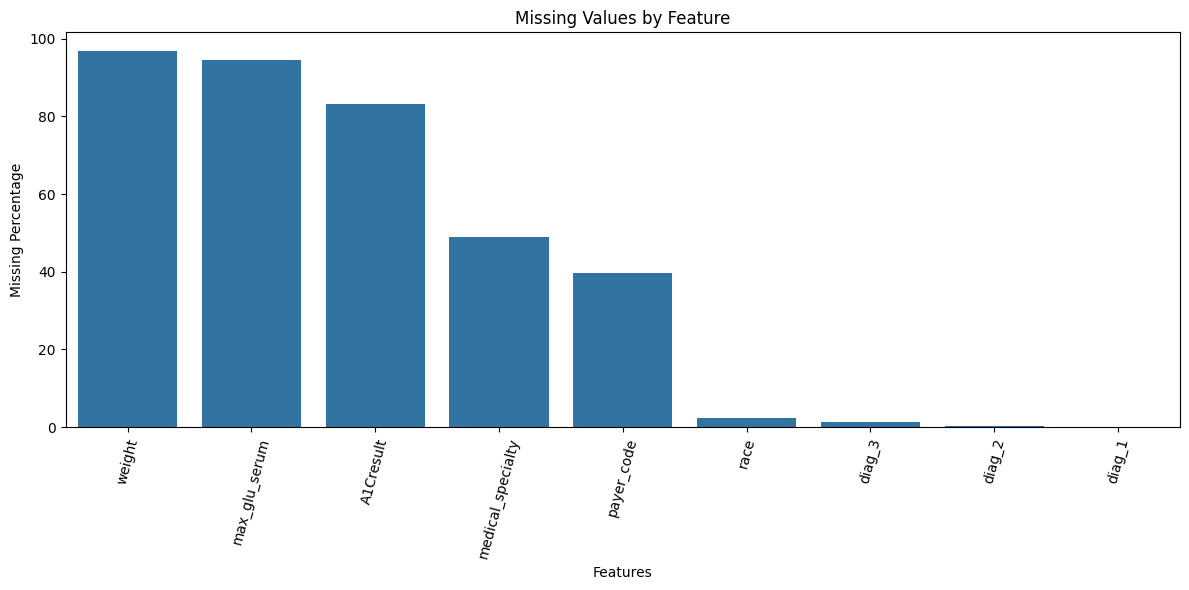

In [ ]:
missing_data = missing_summary[
    missing_summary["Missing_Count"] > 0
]

plt.figure(figsize=(12, 6))

sns.barplot(
    data=missing_data.reset_index(),
    x="index",
    y="Missing_Percentage"
)

plt.title("Missing Values by Feature")
plt.xlabel("Features")
plt.ylabel("Missing Percentage")

plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [ ]:
numeric_features = X_train_clean.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train_clean.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:", len(numeric_features))

print("\nCategorical Features:", len(categorical_features))

print("\nNumerical Columns:")
print(numeric_features)

print("\nCategorical Columns:")
print(categorical_features)

Numerical Features: 11

Categorical Features: 36

Numerical Columns:
['admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

Categorical Columns:
['race', 'gender', 'age', 'weight', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']


In [ ]:
X_val_clean = X_val.replace("?", np.nan)

X_test_clean = X_test.replace("?", np.nan)

In [ ]:
cleaned_splits = {
    "X_train": X_train_clean,
    "X_val": X_val_clean,
    "X_test": X_test_clean,
    "y_train": y_train,
    "y_val": y_val,
    "y_test": y_test
}

save_path = os.path.join(
    PROJECT_PATH,
    "processed_data",
    "day4_cleaned_splits.joblib"
)

joblib.dump(cleaned_splits, save_path)

print("Day 4 cleaned data saved successfully!")

print("Location:", save_path)

print("File exists:", os.path.exists(save_path))

Day 4 cleaned data saved successfully!
Location: /content/drive/MyDrive/Machine learing project/processed_data/day4_cleaned_splits.joblib
File exists: True


In [ ]:
check_columns = [
    "weight",
    "max_glu_serum",
    "A1Cresult",
    "medical_specialty",
    "payer_code"
]

for col in check_columns:

    print("\n", "=" * 40)
    print("Column:", col)

    print(
        df[col]
        .value_counts(dropna=False)
        .head(10)
    )


Column: weight
weight
?            98569
[75-100)      1336
[50-75)        897
[100-125)      625
[125-150)      145
[25-50)         97
[0-25)          48
[150-175)       35
[175-200)       11
>200             3
Name: count, dtype: int64

Column: max_glu_serum
max_glu_serum
NaN     96420
Norm     2597
>200     1485
>300     1264
Name: count, dtype: int64

Column: A1Cresult
A1Cresult
NaN     84748
>8       8216
Norm     4990
>7       3812
Name: count, dtype: int64

Column: medical_specialty
medical_specialty
?                             49949
InternalMedicine              14635
Emergency/Trauma               7565
Family/GeneralPractice         7440
Cardiology                     5352
Surgery-General                3099
Nephrology                     1613
Orthopedics                    1400
Orthopedics-Reconstructive     1233
Radiologist                    1140
Name: count, dtype: int64

Column: payer_code
payer_code
?     40256
MC    32439
HM     6274
SP     5007
BC     4655
MD     35

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import joblib
import os

import sklearn

print("Scikit-learn Version:", sklearn.__version__)

Scikit-learn Version: 1.6.1


In [ ]:
PROJECT_PATH = "/content/drive/MyDrive/Machine learing project"

dataset_path = os.path.join(
    PROJECT_PATH,
    "diabetes+130-us+hospitals+for+years+1999-2008",
    "diabetic_data.csv"
)

day4_path = os.path.join(
    PROJECT_PATH,
    "processed_data",
    "day4_cleaned_splits.joblib"
)

In [ ]:
day4 = joblib.load(day4_path)

X_train_previous = day4["X_train"]
X_val_previous = day4["X_val"]
X_test_previous = day4["X_test"]

y_train = day4["y_train"]
y_val = day4["y_val"]
y_test = day4["y_test"]

print("Day 4 data loaded successfully!")

Day 4 data loaded successfully!


In [ ]:
df_raw = pd.read_csv(
    dataset_path,
    keep_default_na=False
)

print("Original Dataset:", df_raw.shape)

Original Dataset: (101766, 50)


In [ ]:
def rebuild_clean_split(previous_X):

    X = df_raw.loc[
        previous_X.index,
        previous_X.columns
    ].copy()

    # Actual missing placeholders
    X = X.replace({
        "?": np.nan,
        "": np.nan
    })

    # Preserve laboratory test information
    lab_columns = [
        "max_glu_serum",
        "A1Cresult"
    ]

    for col in lab_columns:

        X[col] = X[col].replace(
            "None",
            "Not_Measured"
        )

    return X

In [ ]:
X_train_clean = rebuild_clean_split(
    X_train_previous
)

X_val_clean = rebuild_clean_split(
    X_val_previous
)

X_test_clean = rebuild_clean_split(
    X_test_previous
)

print("Original categorical values restored!")

Original categorical values restored!


In [ ]:
for col in ["max_glu_serum", "A1Cresult"]:

    print("\nColumn:", col)

    print(
        X_train_clean[col].value_counts(
            dropna=False
        )
    )


Column: max_glu_serum
max_glu_serum
Not_Measured    61633
Norm             1703
>200              981
>300              829
Name: count, dtype: int64

Column: A1Cresult
A1Cresult
Not_Measured    54253
>8               5260
Norm             3171
>7               2462
Name: count, dtype: int64


In [ ]:
for X in [
    X_train_clean,
    X_val_clean,
    X_test_clean
]:

    X["weight_recorded"] = (
        X["weight"]
        .notna()
        .astype(int)
    )

    X.drop(
        columns=["weight"],
        inplace=True
    )

print("Weight feature processed!")

Weight feature processed!


In [ ]:
id_categorical = [
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id"
]

numeric_features = [
    col for col in
    X_train_clean.select_dtypes(
        include=np.number
    ).columns
    if col not in id_categorical
]

categorical_features = [
    col for col in X_train_clean.columns
    if col not in numeric_features
]

print("Numerical Features:", len(numeric_features))

print("Categorical Features:", len(categorical_features))

Numerical Features: 9
Categorical Features: 38


In [ ]:
for X in [
    X_train_clean,
    X_val_clean,
    X_test_clean
]:

    for col in categorical_features:

        X[col] = X[col].map(
            lambda value:
                np.nan if pd.isna(value)
                else str(value)
        )

print("Categorical features converted to strings!")

Categorical features converted to strings!


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

numeric_pipeline = Pipeline(
    steps=[

        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "scaler",
            StandardScaler()
        )

    ]
)

In [ ]:
from sklearn.impute import SimpleImputer

from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline(
    steps=[

        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Unknown"
            )
        ),

        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=20,
                sparse_output=True
            )
        )

    ]
)

In [ ]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(

    transformers=[

        (
            "num",
            numeric_pipeline,
            numeric_features
        ),

        (
            "cat",
            categorical_pipeline,
            categorical_features
        )

    ],

    remainder="drop"

)

In [ ]:
# Fit and transform training data

X_train_processed = preprocessor.fit_transform(
    X_train_clean
)

# Transform validation data

X_val_processed = preprocessor.transform(
    X_val_clean
)

# Transform testing data

X_test_processed = preprocessor.transform(
    X_test_clean
)

print("Preprocessing completed!")

Preprocessing completed!


In [ ]:
print(
    "Training Shape:",
    X_train_processed.shape
)

print(
    "Validation Shape:",
    X_val_processed.shape
)

print(
    "Testing Shape:",
    X_test_processed.shape
)

Training Shape: (65146, 937)
Validation Shape: (16467, 937)
Testing Shape: (20153, 937)


In [ ]:
from scipy import sparse

print(
    "Is Sparse Matrix:",
    sparse.issparse(X_train_processed)
)

Is Sparse Matrix: True


In [ ]:
def check_nan(matrix):

    if sparse.issparse(matrix):

        return np.isnan(
            matrix.data
        ).any()

    return np.isnan(matrix).any()


print(
    "Training contains NaN:",
    check_nan(X_train_processed)
)

print(
    "Validation contains NaN:",
    check_nan(X_val_processed)
)

print(
    "Testing contains NaN:",
    check_nan(X_test_processed)
)

Training contains NaN: False
Validation contains NaN: False
Testing contains NaN: False


In [ ]:
processed_path = os.path.join(
    PROJECT_PATH,
    "processed_data"
)

models_path = os.path.join(
    PROJECT_PATH,
    "models"
)

os.makedirs(processed_path, exist_ok=True)
os.makedirs(models_path, exist_ok=True)

In [ ]:
feature_names = preprocessor.get_feature_names_out()

day5_artifacts = {

    "X_train_processed": X_train_processed,

    "X_val_processed": X_val_processed,

    "X_test_processed": X_test_processed,

    "y_train": y_train,

    "y_val": y_val,

    "y_test": y_test,

    "feature_names": feature_names,

    "numeric_features": numeric_features,

    "categorical_features": categorical_features

}

In [ ]:
day5_save_path = os.path.join(
    processed_path,
    "day5_preprocessed_splits.joblib"
)

joblib.dump(
    day5_artifacts,
    day5_save_path,
    compress=3
)

print("Day 5 processed data saved!")

Day 5 processed data saved!


In [ ]:
preprocessor_save_path = os.path.join(
    models_path,
    "preprocessor.joblib"
)

joblib.dump(
    preprocessor,
    preprocessor_save_path,
    compress=3
)

print("Preprocessing pipeline saved!")

Preprocessing pipeline saved!


In [ ]:
print(
    "Processed data exists:",
    os.path.exists(day5_save_path)
)

print(
    "Preprocessor exists:",
    os.path.exists(preprocessor_save_path)
)

print(
    "Processed file size:",
    round(
        os.path.getsize(day5_save_path) / (1024 * 1024),
        2
    ),
    "MB"
)

Processed data exists: True
Preprocessor exists: True
Processed file size: 3.89 MB


In [ ]:
df_raw = pd.read_csv(
    dataset_path,
    keep_default_na=False
)

print("Original Dataset:", df_raw.shape)

Original Dataset: (101766, 50)


In [ ]:
def rebuild_clean_split(previous_X):

    X = df_raw.loc[
        previous_X.index,
        previous_X.columns
    ].copy()

    X = X.replace({
        "?": np.nan,
        "": np.nan
    })

    lab_columns = [
        "max_glu_serum",
        "A1Cresult"
    ]

    for col in lab_columns:

        X[col] = X[col].replace(
            "None",
            "Not_Measured"
        )

    return X

In [ ]:
X_train_clean = rebuild_clean_split(X_train_previous)

X_val_clean = rebuild_clean_split(X_val_previous)

X_test_clean = rebuild_clean_split(X_test_previous)

In [ ]:
for col in ["max_glu_serum", "A1Cresult"]:

    print("\nColumn:", col)

    print(
        X_train_clean[col].value_counts(
            dropna=False
        )
    )


Column: max_glu_serum
max_glu_serum
Not_Measured    61633
Norm             1703
>200              981
>300              829
Name: count, dtype: int64

Column: A1Cresult
A1Cresult
Not_Measured    54253
>8               5260
Norm             3171
>7               2462
Name: count, dtype: int64


In [ ]:
for X in [
    X_train_clean,
    X_val_clean,
    X_test_clean
]:

    X["weight_recorded"] = (
        X["weight"].notna().astype(int)
    )

    X.drop(
        columns=["weight"],
        inplace=True
    )

print("Weight feature engineering completed!")

Weight feature engineering completed!


In [ ]:
constant_features = [
    col for col in X_train_clean.columns
    if X_train_clean[col].nunique(dropna=True) <= 1
]

print("Constant Features:", constant_features)

Constant Features: ['acetohexamide', 'examide', 'citoglipton', 'glimepiride-pioglitazone', 'metformin-pioglitazone']


In [ ]:
for X in [
    X_train_clean,
    X_val_clean,
    X_test_clean
]:

    X.drop(
        columns=constant_features,
        inplace=True
    )

print("Constant features removed!")

Constant features removed!


In [ ]:
id_categorical = [
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id"
]

numeric_features = [
    col for col in
    X_train_clean.select_dtypes(
        include=np.number
    ).columns
    if col not in id_categorical
]

categorical_features = [
    col for col in X_train_clean.columns
    if col not in numeric_features
]

print("Numerical Features:", len(numeric_features))

print("Categorical Features:", len(categorical_features))

print("\nNumerical:")
print(numeric_features)

print("\nCategorical:")
print(categorical_features)

Numerical Features: 9
Categorical Features: 33

Numerical:
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'weight_recorded']

Categorical:
['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'metformin-rosiglitazone', 'change', 'diabetesMed']


In [ ]:
for X in [
    X_train_clean,
    X_val_clean,
    X_test_clean
]:

    for col in categorical_features:

        X[col] = X[col].map(
            lambda value:
                np.nan if pd.isna(value)
                else str(value)
        )

print("Categorical conversion completed!")

Categorical conversion completed!


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_pipeline = Pipeline(
    steps=[

        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "scaler",
            StandardScaler()
        )

    ]
)

print("Numerical Pipeline Created!")

Numerical Pipeline Created!


In [ ]:
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline(
    steps=[

        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Unknown"
            )
        ),

        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=20,
                sparse_output=True
            )
        )

    ]
)

print("Categorical Pipeline Created!")

Categorical Pipeline Created!


In [ ]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(

    transformers=[

        (
            "num",
            numeric_pipeline,
            numeric_features
        ),

        (
            "cat",
            categorical_pipeline,
            categorical_features
        )

    ],

    remainder="drop"
)

print("Complete Preprocessor Created!")

Complete Preprocessor Created!


In [ ]:
X_train_processed = preprocessor.fit_transform(
    X_train_clean
)

X_val_processed = preprocessor.transform(
    X_val_clean
)

X_test_processed = preprocessor.transform(
    X_test_clean
)

print("Preprocessing Completed!")

Preprocessing Completed!


In [ ]:
print("Training Shape:", X_train_processed.shape)

print("Validation Shape:", X_val_processed.shape)

print("Testing Shape:", X_test_processed.shape)

Training Shape: (65146, 932)
Validation Shape: (16467, 932)
Testing Shape: (20153, 932)


In [ ]:
from scipy import sparse

print(
    "Is Sparse Matrix:",
    sparse.issparse(X_train_processed)
)

Is Sparse Matrix: True


In [ ]:
def check_nan(matrix):

    if sparse.issparse(matrix):
        return np.isnan(matrix.data).any()

    return np.isnan(matrix).any()


print(
    "Training NaN:",
    check_nan(X_train_processed)
)

print(
    "Validation NaN:",
    check_nan(X_val_processed)
)

print(
    "Testing NaN:",
    check_nan(X_test_processed)
)

Training NaN: False
Validation NaN: False
Testing NaN: False


In [ ]:
processed_path = os.path.join(
    PROJECT_PATH,
    "processed_data"
)

models_path = os.path.join(
    PROJECT_PATH,
    "models"
)

os.makedirs(processed_path, exist_ok=True)
os.makedirs(models_path, exist_ok=True)

In [ ]:
feature_names = preprocessor.get_feature_names_out()

In [ ]:
day5_artifacts = {

    "X_train_processed": X_train_processed,
    "X_val_processed": X_val_processed,
    "X_test_processed": X_test_processed,

    "y_train": y_train,
    "y_val": y_val,
    "y_test": y_test,

    "feature_names": feature_names,

    "numeric_features": numeric_features,
    "categorical_features": categorical_features,

    "constant_features": constant_features

}

In [ ]:
day5_save_path = os.path.join(
    processed_path,
    "day5_preprocessed_splits.joblib"
)

joblib.dump(
    day5_artifacts,
    day5_save_path,
    compress=3
)

['/content/drive/MyDrive/Machine learing project/processed_data/day5_preprocessed_splits.joblib']

In [ ]:
preprocessor_save_path = os.path.join(
    models_path,
    "preprocessor.joblib"
)

joblib.dump(
    preprocessor,
    preprocessor_save_path,
    compress=3
)

['/content/drive/MyDrive/Machine learing project/models/preprocessor.joblib']

In [ ]:
print(
    "Processed data exists:",
    os.path.exists(day5_save_path)
)

print(
    "Preprocessor exists:",
    os.path.exists(preprocessor_save_path)
)

print(
    "Feature count:",
    len(feature_names)
)

Processed data exists: True
Preprocessor exists: True
Feature count: 932


In [ ]:
print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)

Training: (65146, 932)
Validation: (16467, 932)
Testing: (20153, 932)


In [ ]:
print("Training NaN:", check_nan(X_train_processed))
print("Validation NaN:", check_nan(X_val_processed))
print("Testing NaN:", check_nan(X_test_processed))

Training NaN: False
Validation NaN: False
Testing NaN: False


In [ ]:
import pandas as pd
import numpy as np
import joblib
import os
import json

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import sparse

PROJECT_PATH = "/content/drive/MyDrive/Machine learing project"

day5_path = os.path.join(
    PROJECT_PATH,
    "processed_data",
    "day5_preprocessed_splits.joblib"
)

day5 = joblib.load(day5_path)

X_train = day5["X_train_processed"]
X_val = day5["X_val_processed"]

y_train = day5["y_train"]
y_val = day5["y_val"]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Features:", len(day5["feature_names"]))

Training: (65146, 932)
Validation: (16467, 932)
Features: 932


In [ ]:
from sklearn.dummy import DummyClassifier

dummy_model = DummyClassifier(
    strategy="most_frequent"
)

dummy_model.fit(
    X_train,
    y_train
)

dummy_pred = dummy_model.predict(X_val)

print("Dummy Classifier trained!")

Dummy Classifier trained!


In [ ]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    C=1.0,
    penalty="l2",
    solver="liblinear",
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

print("Training Started...")

logistic_model.fit(
    X_train,
    y_train
)

print("Training Completed!")

print("Iterations:", logistic_model.n_iter_)
print("Classes:", logistic_model.classes_)
print("Number of features:", len(logistic_model.coef_[0]))

Training Started...
Training Completed!
Iterations: [9]
Classes: [0 1]
Number of features: 932


In [ ]:
y_val_pred = logistic_model.predict(X_val)

y_val_probability = logistic_model.predict_proba(X_val)[:, 1]

print("Predictions generated!")

print("\nFirst 10 predicted classes:")
print(y_val_pred[:10])

print("\nFirst 10 probabilities:")
print(y_val_probability[:10])

Predictions generated!

First 10 predicted classes:
[0 0 0 1 0 0 0 0 0 0]

First 10 probabilities:
[0.02105989 0.31460796 0.46206989 0.6083833  0.35531751 0.22028127
 0.4922757  0.46263934 0.2462677  0.45924383]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score
)

def evaluate_model(name, y_true, y_pred, y_prob=None):

    results = {
        "Model": name,

        "Accuracy": accuracy_score(
            y_true, y_pred
        ),

        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),

        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),

        "F1_Score": f1_score(
            y_true, y_pred, zero_division=0
        ),

        "Balanced_Accuracy": balanced_accuracy_score(
            y_true, y_pred
        )
    }

    if y_prob is not None:

        results["ROC_AUC"] = roc_auc_score(
            y_true, y_prob
        )

        results["Average_Precision"] = average_precision_score(
            y_true, y_prob
        )

    return results

In [ ]:
dummy_probability = dummy_model.predict_proba(X_val)[:, 1]

In [ ]:
logistic_results = evaluate_model(
    "Logistic Regression",
    y_val,
    y_val_pred,
    y_val_probability
)

dummy_results = evaluate_model(
    "Dummy Classifier",
    y_val,
    dummy_pred,
    dummy_probability
)

comparison_df = pd.DataFrame([
    logistic_results,
    dummy_results
])

print(comparison_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1_Score  Balanced_Accuracy  ROC_AUC  Average_Precision
Logistic Regression    0.6541     0.1765  0.5551    0.2679              0.611   0.6596             0.2235
   Dummy Classifier    0.8860     0.0000  0.0000    0.0000              0.500   0.5000             0.1140


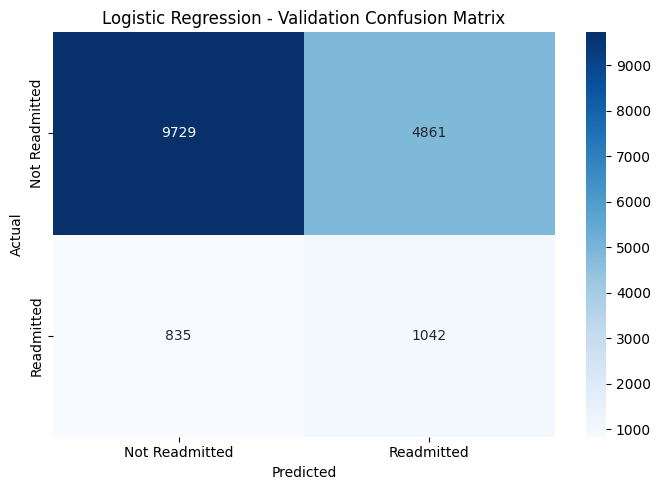

TN: 9729
FP: 4861
FN: 835
TP: 1042


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Not Readmitted",
        "Readmitted"
    ],
    yticklabels=[
        "Not Readmitted",
        "Readmitted"
    ]
)

plt.title("Logistic Regression - Validation Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

print("TN:", cm[0, 0])
print("FP:", cm[0, 1])
print("FN:", cm[1, 0])
print("TP:", cm[1, 1])

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_val,
        y_val_pred,
        labels=[0, 1],
        target_names=[
            "Not Readmitted",
            "Readmitted"
        ],
        zero_division=0
    )
)

                precision    recall  f1-score   support

Not Readmitted       0.92      0.67      0.77     14590
    Readmitted       0.18      0.56      0.27      1877

      accuracy                           0.65     16467
     macro avg       0.55      0.61      0.52     16467
  weighted avg       0.84      0.65      0.72     16467



In [ ]:
models_path = os.path.join(
    PROJECT_PATH,
    "models"
)

results_path = os.path.join(
    PROJECT_PATH,
    "results"
)

os.makedirs(models_path, exist_ok=True)
os.makedirs(results_path, exist_ok=True)

In [ ]:
model_path = os.path.join(
    models_path,
    "logistic_regression_baseline.joblib"
)

joblib.dump(
    logistic_model,
    model_path,
    compress=3
)

print("Model saved:", os.path.exists(model_path))

Model saved: True


In [ ]:
metrics_path = os.path.join(
    results_path,
    "day6_logistic_regression_metrics.json"
)

with open(metrics_path, "w") as file:

    json.dump(
        {
            "logistic_regression": logistic_results,
            "dummy_classifier": dummy_results,
            "confusion_matrix": cm.tolist(),
            "threshold": 0.5,
            "evaluation_dataset": "Validation"
        },
        file,
        indent=4
    )

print("Metrics saved:", os.path.exists(metrics_path))

Metrics saved: True


In [ ]:
validation_results = pd.DataFrame({
    "Actual": np.asarray(y_val),
    "Predicted": y_val_pred,
    "Readmission_Probability": y_val_probability
})

prediction_path = os.path.join(
    results_path,
    "day6_validation_predictions.csv"
)

validation_results.to_csv(
    prediction_path,
    index=False
)

print("Predictions saved:", os.path.exists(prediction_path))

Predictions saved: True


In [ ]:
print("Confusion Matrix:")

print(cm)

print("\nTN:", cm[0, 0])
print("FP:", cm[0, 1])
print("FN:", cm[1, 0])
print("TP:", cm[1, 1])

print("\nPredicted Class Distribution:")

print(pd.Series(y_val_pred).value_counts())

Confusion Matrix:
[[9729 4861]
 [ 835 1042]]

TN: 9729
FP: 4861
FN: 835
TP: 1042

Predicted Class Distribution:
0    10564
1     5903
Name: count, dtype: int64


In [ ]:
import os

PROJECT_PATH = "/content/drive/MyDrive/Machine learing project"

print("Project folder exists:", os.path.exists(PROJECT_PATH))
print("\nProject folder contents:")

for item in os.listdir(PROJECT_PATH):
    print(item)

print("\nGit folders found:")

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    if ".git" in dirs:
        print(os.path.join(root, ".git"))
        dirs.remove(".git")

Project folder exists: True

Project folder contents:
diabetes+130-us+hospitals+for+years+1999-2008
processed_data
models
results
notebooks
reports
presentation

Git folders found:


In [ ]:
import os

REPO_URL = "https://github.com/PredictiveHealth-AI/hospital-patient-readmission-prediction.git"
CLONE_PATH = "/content/hospital-patient-readmission-prediction"

if not os.path.exists(CLONE_PATH):
    !git clone {REPO_URL} {CLONE_PATH}
else:
    print("Repository folder already exists.")

%cd /content/hospital-patient-readmission-prediction

!git branch -a
!git status
!git log -5 --oneline

Cloning into '/content/hospital-patient-readmission-prediction'...
remote: Enumerating objects: 8, done.
remote: Counting objects: 100% (8/8), done.
remote: Compressing objects: 100% (8/8), done.
remote: Total 8 (delta 1), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (8/8), 215.18 KiB | 9.78 MiB/s, done.
Resolving deltas: 100% (1/1), done.
/content/hospital-patient-readmission-prediction
* main
  remotes/origin/Demo-Main
  remotes/origin/HEAD -> origin/main
  remotes/origin/main
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
b5fa711 (HEAD -> main, origin/main, origin/HEAD) Initial commit


In [ ]:
%cd /content/hospital-patient-readmission-prediction

!git fetch origin

print("MAIN branch:")
!git log origin/main --oneline -5

print("\nDEMO-MAIN branch:")
!git log origin/Demo-Main --oneline -10

print("\nBranch differences:")
!git diff --stat origin/main origin/Demo-Main

print("\nFiles in Demo-Main:")
!git ls-tree -r --name-only origin/Demo-Main

/content/hospital-patient-readmission-prediction
MAIN branch:
b5fa711 (HEAD -> main, origin/main, origin/HEAD) Initial commit

DEMO-MAIN branch:
cd5c9a4 (origin/Demo-Main) Created using Colab
b5fa711 (HEAD -> main, origin/main, origin/HEAD) Initial commit

Branch differences:
 notebooks/Group8_Readmission_Prediction.ipynb | 3678 +++++++++++++++++++++++++
 1 file changed, 3678 insertions(+)

Files in Demo-Main:
.gitignore
README.md
notebooks/Group8_Readmission_Prediction.ipynb


In [ ]:
%cd /content/hospital-patient-readmission-prediction

!git switch -c feature/day-6-logistic-regression origin/Demo-Main

print("\nCurrent branch:")
!git branch --show-current

print("\nGit status:")
!git status

/content/hospital-patient-readmission-prediction
branch 'feature/day-6-logistic-regression' set up to track 'origin/Demo-Main'.
Switched to a new branch 'feature/day-6-logistic-regression'

Current branch:
feature/day-6-logistic-regression

Git status:
On branch feature/day-6-logistic-regression
Your branch is up to date with 'origin/Demo-Main'.

nothing to commit, working tree clean


In [ ]:
import os
import hashlib

DRIVE_PATH = "/content/drive/MyDrive/Machine learing project"
REPO_PATH = "/content/hospital-patient-readmission-prediction"

def file_info(path):
    if not os.path.isfile(path):
        return "File not found"

    size = os.path.getsize(path)

    with open(path, "rb") as f:
        checksum = hashlib.sha256(f.read()).hexdigest()

    return {
        "size_bytes": size,
        "sha256": checksum
    }

print("DRIVE NOTEBOOK:")
drive_notebook = os.path.join(
    DRIVE_PATH, "notebooks", "Group8_Readmission_Prediction.ipynb"
)
print(file_info(drive_notebook))

print("\nGITHUB NOTEBOOK:")
repo_notebook = os.path.join(
    REPO_PATH, "notebooks", "Group8_Readmission_Prediction.ipynb"
)
print(file_info(repo_notebook))

print("\nDRIVE RESULTS FILES:")
for root, dirs, files in os.walk(os.path.join(DRIVE_PATH, "results")):
    for name in files:
        print(os.path.relpath(os.path.join(root, name), DRIVE_PATH))

print("\nGITIGNORE:")
gitignore = os.path.join(REPO_PATH, ".gitignore")
if os.path.exists(gitignore):
    with open(gitignore, "r") as f:
        print(f.read())

DRIVE NOTEBOOK:
File not found

GITHUB NOTEBOOK:
{'size_bytes': 403007, 'sha256': '0369f24a1283aa2879430b477584bea117f0d1712e21bd4511715943dd5aa727'}

DRIVE RESULTS FILES:
results/day6_logistic_regression_metrics.json
results/day6_validation_predictions.csv

GITIGNORE:
# Byte-compiled / optimized / DLL files
__pycache__/
*.py[codz]
*$py.class

# C extensions
*.so

# Distribution / packaging
.Python
build/
develop-eggs/
dist/
downloads/
eggs/
.eggs/
lib/
lib64/
parts/
sdist/
var/
wheels/
share/python-wheels/
*.egg-info/
.installed.cfg
*.egg
MANIFEST

# PyInstaller
#   Usually these files are written by a python script from a template
#   before PyInstaller builds the exe, so as to inject date/other infos into it.
*.manifest
*.spec

# Installer logs
pip-log.txt
pip-delete-this-directory.txt

# Unit test / coverage reports
htmlcov/
.tox/
.nox/
.coverage
.coverage.*
.cache
nosetests.xml
coverage.xml
*.cover
*.py.cover
*.lcov
.hypothesis/
.pytest_cache/
cover/

# Translations
*.mo
*.pot

# 

In [ ]:
import os

PROJECT_PATH = "/content/drive/MyDrive/Machine learing project"

for root, dirs, files in os.walk(PROJECT_PATH):
    dirs[:] = [d for d in dirs if d not in [
        "diabetes+130-us+hospitals+for+years+1999-2008",
        ".ipynb_checkpoints"
    ]]

    for file in files:
        if file.endswith(".ipynb"):
            print(os.path.join(root, file))

In [ ]:
%cd /content/hospital-patient-readmission-prediction

!git status
!git branch --show-current
!git ls-files

/content/hospital-patient-readmission-prediction
On branch feature/day-6-logistic-regression
Your branch is up to date with 'origin/Demo-Main'.

nothing to commit, working tree clean
feature/day-6-logistic-regression
.gitignore
README.md
notebooks/Group8_Readmission_Prediction.ipynb


In [ ]:
import os
import shutil

DRIVE_PATH = "/content/drive/MyDrive/Machine learing project"
REPO_PATH = "/content/hospital-patient-readmission-prediction"

# Create results directory if needed
os.makedirs(os.path.join(REPO_PATH, "results"), exist_ok=True)

files_to_copy = [
    "day6_logistic_regression_metrics.json",
    "day6_validation_predictions.csv"
]

for filename in files_to_copy:
    source = os.path.join(DRIVE_PATH, "results", filename)
    destination = os.path.join(REPO_PATH, "results", filename)

    if os.path.exists(source):
        shutil.copy2(source, destination)
        print("Copied:", filename)
    else:
        print("MISSING:", filename)

print("\nRepository results:")
for filename in os.listdir(os.path.join(REPO_PATH, "results")):
    print(filename)

Copied: day6_logistic_regression_metrics.json
Copied: day6_validation_predictions.csv

Repository results:
day6_logistic_regression_metrics.json
day6_validation_predictions.csv


In [ ]:
%cd /content/hospital-patient-readmission-prediction

import json
import pandas as pd

metrics_path = "results/day6_logistic_regression_metrics.json"
predictions_path = "results/day6_validation_predictions.csv"

# Validate JSON
with open(metrics_path, "r") as f:
    metrics = json.load(f)

print("Metrics JSON: VALID")
print(json.dumps(metrics, indent=2))

# Validate CSV
predictions = pd.read_csv(predictions_path)

print("\nPredictions CSV: VALID")
print("Shape:", predictions.shape)
print("Columns:", predictions.columns.tolist())
print("\nFirst 5 rows:")
display(predictions.head())

print("\nGit diff summary:")
!git status --short
!git diff --stat

/content/hospital-patient-readmission-prediction
Metrics JSON: VALID
{
  "logistic_regression": {
    "Model": "Logistic Regression",
    "Accuracy": 0.6540960709297383,
    "Precision": 0.1765204133491445,
    "Recall": 0.5551411827384124,
    "F1_Score": 0.267866323907455,
    "Balanced_Accuracy": 0.6109838881478217,
    "ROC_AUC": 0.6595766800083109,
    "Average_Precision": 0.22348215272377925
  },
  "dummy_classifier": {
    "Model": "Dummy Classifier",
    "Accuracy": 0.8860144531487217,
    "Precision": 0.0,
    "Recall": 0.0,
    "F1_Score": 0.0,
    "Balanced_Accuracy": 0.5,
    "ROC_AUC": 0.5,
    "Average_Precision": 0.11398554685127832
  },
  "confusion_matrix": [
    [
      9729,
      4861
    ],
    [
      835,
      1042
    ]
  ],
  "threshold": 0.5,
  "evaluation_dataset": "Validation"
}

Predictions CSV: VALID
Shape: (16467, 3)
Columns: ['Actual', 'Predicted', 'Readmission_Probability']

First 5 rows:


,Actual,Predicted,Readmission_Probability
0,0,0,0.021060
1,0,0,0.314608
2,0,0,0.462070
3,0,1,0.608383
4,1,0,0.355318



Git diff summary:
?? results/


In [ ]:
%cd /content/hospital-patient-readmission-prediction

!git add results/day6_logistic_regression_metrics.json

print("Staged changes:")
!git diff --cached --check
!git diff --cached --stat

/content/hospital-patient-readmission-prediction
Staged changes:
 results/day6_logistic_regression_metrics.json | 34 +++++++++++++++++++++++++++
 1 file changed, 34 insertions(+)


In [ ]:
!git commit -m "feat: add day 6 baseline evaluation metrics"

Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@ab229ffb1f96.(none)')


In [ ]:
!git add results/day6_validation_predictions.csv

!git diff --cached --check
!git diff --cached --stat

 results/day6_logistic_regression_metrics.json |    34 +
 results/day6_validation_predictions.csv       | 16468 ++++++++++++++++++++++++
 2 files changed, 16502 insertions(+)


In [ ]:
!git commit -m "feat: add day 6 validation predictions"

Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@ab229ffb1f96.(none)')


In [ ]:
%cd /content/hospital-patient-readmission-prediction

import os

os.makedirs("reports", exist_ok=True)

content = """# Day 6 - Logistic Regression Baseline

## Objective
Train and evaluate a Logistic Regression baseline model
for the Hospital Patient Readmission Prediction project.

## Dataset
- Dataset: Diabetes 130-US Hospitals
- Evaluation split: Validation
- Validation records: 16,467
- Target: readmitted within 30 days (binary classification)
- Classification threshold: 0.5

## Models
1. Logistic Regression
2. Dummy Classifier (most frequent strategy)

## Logistic Regression Configuration
- C: 1.0
- Penalty: L2
- Solver: liblinear
- Class weight: balanced
- Maximum iterations: 1000
- Random state: 42

## Validation Results

| Metric | Logistic Regression | Dummy Classifier |
|---|---:|---:|
| Accuracy | 0.6541 | 0.8860 |
| Precision | 0.1765 | 0.0000 |
| Recall | 0.5551 | 0.0000 |
| F1-score | 0.2679 | 0.0000 |
| Balanced Accuracy | 0.6110 | 0.5000 |
| ROC-AUC | 0.6596 | 0.5000 |
| Average Precision | 0.2235 | 0.1140 |

## Confusion Matrix

| | Predicted Not Readmitted | Predicted Readmitted |
|---|---:|---:|
| Actual Not Readmitted | 9729 (TN) | 4861 (FP) |
| Actual Readmitted | 835 (FN) | 1042 (TP) |

## Interpretation
The Logistic Regression model detects 55.51% of actual
readmissions at the default threshold of 0.5.

However, precision is 17.65%, indicating a high number of
false-positive predictions.

The Dummy Classifier achieves higher accuracy because of
class imbalance, but it fails to identify any positive cases.

Therefore, accuracy alone is not sufficient to evaluate
this imbalanced classification problem.

## Limitations
- This is a baseline academic model, not a clinically validated system.
- Results are based on the validation dataset.
- Further model comparison and threshold analysis are required.
- The test dataset has not been used for this experiment.

## Output Files
- results/day6_logistic_regression_metrics.json
- results/day6_validation_predictions.csv

## Next Step
Compare the baseline with a Decision Tree classifier.
"""

with open("reports/day6_logistic_regression_report.md", "w") as f:
    f.write(content)

print("Day 6 report created successfully.")

/content/hospital-patient-readmission-prediction
Day 6 report created successfully.


In [ ]:
!git add reports/day6_logistic_regression_report.md
!git diff --cached --check
!git commit -m "docs: document day 6 logistic regression experiment"

Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@ab229ffb1f96.(none)')


In [ ]:
import json

notebook_path = "notebooks/Group8_Readmission_Prediction.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "LogisticRegression",
    "DummyClassifier",
    "confusion_matrix",
    "average_precision_score"
]

for keyword in keywords:
    matches = []

    for i, cell in enumerate(notebook["cells"]):
        source = "".join(cell.get("source", []))
        if keyword in source:
            matches.append(i)

    print(keyword, "-> cells:", matches)

LogisticRegression -> cells: []
DummyClassifier -> cells: []
confusion_matrix -> cells: []
average_precision_score -> cells: []


In [ ]:
!git config --global user.name
!git config --global user.email

In [ ]:
%cd /content/hospital-patient-readmission-prediction

!git status --short

/content/hospital-patient-readmission-prediction
A  reports/day6_logistic_regression_report.md
A  results/day6_logistic_regression_metrics.json
A  results/day6_validation_predictions.csv


In [ ]:
!git commit -m "feat: add day 6 baseline evaluation metrics"

Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@ab229ffb1f96.(none)')


In [ ]:
!git commit -m "feat: add day 6 validation predictions"

Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@ab229ffb1f96.(none)')


In [ ]:
!git commit -m "docs: document day 6 logistic regression experiment"

Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@ab229ffb1f96.(none)')


In [ ]:
!git reset
!git add results/day6_logistic_regression_metrics.json
!git commit -m "feat: add day 6 baseline evaluation metrics"

!git add results/day6_validation_predictions.csv
!git commit -m "feat: add day 6 validation predictions"

!git add reports/day6_logistic_regression_report.md
!git commit -m "docs: document day 6 logistic regression experiment"

Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@ab229ffb1f96.(none)')
Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@ab229ffb1f96.(none)')
Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@ab229ffb1f96.(non

In [ ]:
!git status
!git log -3 --oneline
!git branch --show-current

On branch feature/day-6-logistic-regression
Your branch is up to date with 'origin/Demo-Main'.

Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	new file:   reports/day6_logistic_regression_report.md
	new file:   results/day6_logistic_regression_metrics.json
	new file:   results/day6_validation_predictions.csv

cd5c9a4 (HEAD -> feature/day-6-logistic-regression, origin/Demo-Main) Created using Colab
b5fa711 (origin/main, origin/HEAD, main) Initial commit
feature/day-6-logistic-regression


In [ ]:
!git push -u origin feature/day-6-logistic-regression

fatal: could not read Username for 'https://github.com': No such device or address


In [ ]:
from getpass import getpass

github_token = getpass("Enter GitHub Personal Access Token: ")

Enter GitHub Personal Access Token: ··········


In [ ]:
%cd /content/hospital-patient-readmission-prediction

print("CURRENT BRANCH:")
!git branch --show-current

print("\nLATEST COMMITS:")
!git log -5 --oneline

print("\nGIT STATUS:")
!git status

print("\nREMOTE:")
!git remote -v

/content/hospital-patient-readmission-prediction
CURRENT BRANCH:
feature/day-6-logistic-regression

LATEST COMMITS:
cd5c9a4 (HEAD -> feature/day-6-logistic-regression, origin/Demo-Main) Created using Colab
b5fa711 (origin/main, origin/HEAD, main) Initial commit

GIT STATUS:
On branch feature/day-6-logistic-regression
Your branch is up to date with 'origin/Demo-Main'.

Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	new file:   reports/day6_logistic_regression_report.md
	new file:   results/day6_logistic_regression_metrics.json
	new file:   results/day6_validation_predictions.csv


REMOTE:
origin	https://github.com/PredictiveHealth-AI/hospital-patient-readmission-prediction.git (fetch)
origin	https://github.com/PredictiveHealth-AI/hospital-patient-readmission-prediction.git (push)


In [ ]:
%cd /content/hospital-patient-readmission-prediction

!git config user.name "Paviththiran"
!git config user.email "pavipavi0308@gmail.com"

/content/hospital-patient-readmission-prediction


In [ ]:
!git reset

# Commit 1: Evaluation metrics
!git add results/day6_logistic_regression_metrics.json
!git commit -m "feat: add day 6 baseline evaluation metrics"

# Commit 2: Validation predictions
!git add results/day6_validation_predictions.csv
!git commit -m "feat: add day 6 validation predictions"

# Commit 3: Experiment documentation
!git add reports/day6_logistic_regression_report.md
!git commit -m "docs: document day 6 logistic regression experiment"

[feature/day-6-logistic-regression 71d8260] feat: add day 6 baseline evaluation metrics
 1 file changed, 34 insertions(+)
 create mode 100644 results/day6_logistic_regression_metrics.json
[feature/day-6-logistic-regression 324cd34] feat: add day 6 validation predictions
 1 file changed, 16468 insertions(+)
 create mode 100644 results/day6_validation_predictions.csv
[feature/day-6-logistic-regression 4f03273] docs: document day 6 logistic regression experiment
 1 file changed, 69 insertions(+)
 create mode 100644 reports/day6_logistic_regression_report.md


In [ ]:
!git log -3 --oneline
!git status
!git branch --show-current

4f03273 (HEAD -> feature/day-6-logistic-regression) docs: document day 6 logistic regression experiment
324cd34 feat: add day 6 validation predictions
71d8260 feat: add day 6 baseline evaluation metrics
On branch feature/day-6-logistic-regression
Your branch is ahead of 'origin/Demo-Main' by 3 commits.
  (use "git push" to publish your local commits)

nothing to commit, working tree clean
feature/day-6-logistic-regression


In [ ]:
from getpass import getpass
import subprocess
import base64

token = getpass("GitHub PAT: ")

auth = base64.b64encode(
    f"x-access-token:{token}".encode()
).decode()

result = subprocess.run(
    [
        "git",
        "-c", f"http.extraheader=AUTHORIZATION: basic {auth}",
        "push", "-u", "origin",
        "feature/day-6-logistic-regression"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)
print("SUCCESS" if result.returncode == 0 else "FAILED")

token = None
auth = None

GitHub PAT: ··········

remote: Permission to PredictiveHealth-AI/hospital-patient-readmission-prediction.git denied to kpavith-dev.
fatal: unable to access 'https://github.com/PredictiveHealth-AI/hospital-patient-readmission-prediction.git/': The requested URL returned error: 403

FAILED


In [ ]:
%cd /content/hospital-patient-readmission-prediction

!git status
!git log -3 --oneline

/content/hospital-patient-readmission-prediction
On branch feature/day-6-logistic-regression
Your branch is ahead of 'origin/Demo-Main' by 3 commits.
  (use "git push" to publish your local commits)

nothing to commit, working tree clean
4f03273 (HEAD -> feature/day-6-logistic-regression) docs: document day 6 logistic regression experiment
324cd34 feat: add day 6 validation predictions
71d8260 feat: add day 6 baseline evaluation metrics


In [ ]:
!git push -u origin feature/day-6-logistic-regression

fatal: could not read Username for 'https://github.com': No such device or address


In [ ]:
import subprocess
import base64
from getpass import getpass

# 1. Move to repository directory
%cd /content/hospital-patient-readmission-prediction

# 2. Securely get the Personal Access Token
token = getpass("Please enter your GitHub PAT: ")

# 3. Create the basic auth header safely
auth = base64.b64encode(f"x-access-token:{token}".encode()).decode()

# 4. Perform the push command with the temporary basic auth header
print("Attempting to push to origin...")
result = subprocess.run(
    [
        "git",
        "-c", f"http.extraheader=AUTHORIZATION: basic {auth}",
        "push", "-u", "origin",
        "feature/day-6-logistic-regression"
    ],
    capture_output=True,
    text=True
)

print("=== STDOUT ===")
print(result.stdout)
print("=== STDERR ===")
print(result.stderr)

if result.returncode == 0:
    print("\nSUCCESS: Changes successfully pushed to feature/day-6-logistic-regression!")
else:
    print("\nFAILED: Push failed.")
    if "403" in result.stderr or "denied" in result.stderr:
        print("\nDIAGNOSTIC - HTTP 403 Forbidden Detected:\n"
              "1. Your token is valid, but the account 'kpavith-dev' does not have Write/Collaborator permissions on the target repository 'PredictiveHealth-AI/hospital-patient-readmission-prediction'.\n"
              "2. Alternatively, if this is a Fine-Grained Personal Access Token, ensure that 'All Repositories' or specifically this repository is selected under Repository Access, and 'Contents' read/write permission is allowed.\n"
              "3. Please verify your repository invite or collaborator status on GitHub.")

# Clear credentials
token = None
auth = None

/content/hospital-patient-readmission-prediction


In [ ]:
# Final verification of the local git status and commit history
!git branch -a
!git status
!git log -5 --oneline

In [ ]:
import subprocess

# Confirm current branch
subprocess.run(["git", "branch", "--show-current"])


CompletedProcess(args=['git', 'branch', '--show-current'], returncode=128)

In [ ]:
import os
import subprocess

# Change to the correct repository folder first
repo_path = "/content/hospital-patient-readmission-prediction"
if os.path.exists(repo_path):
    os.chdir(repo_path)
    print("Successfully changed directory to:", os.getcwd())

    # Confirm current branch securely
    result = subprocess.run(["git", "branch", "--show-current"], capture_output=True, text=True)
    print("Current Active Branch:", result.stdout.strip())
else:
    print(f"Repository directory '{repo_path}' does not exist. Please clone it first.")

Repository directory '/content/hospital-patient-readmission-prediction' does not exist. Please clone it first.


In [ ]:
import os

REPO_URL = "https://github.com/PredictiveHealth-AI/hospital-patient-readmission-prediction.git"
CLONE_PATH = "/content/hospital-patient-readmission-prediction"

if not os.path.exists(CLONE_PATH):
    print("Cloning repository...")
    !git clone {REPO_URL} {CLONE_PATH}
else:
    print("Repository already exists.")

# Switch to the directory and confirm
%cd /content/hospital-patient-readmission-prediction
!git status

Cloning repository...
Cloning into '/content/hospital-patient-readmission-prediction'...
remote: Enumerating objects: 8, done.
remote: Counting objects: 100% (8/8), done.
remote: Compressing objects: 100% (8/8), done.
remote: Total 8 (delta 1), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (8/8), 215.18 KiB | 1.22 MiB/s, done.
Resolving deltas: 100% (1/1), done.
/content/hospital-patient-readmission-prediction
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [ ]:
import os
import shutil

# 1. Switch working directory to cloned repo
%cd /content/hospital-patient-readmission-prediction

# 2. Re-create and switch to the feature/day-6-logistic-regression branch from Demo-Main
print("Fetching branches...")
!git fetch origin
print("Switching to feature branch...")
!git switch -c feature/day-6-logistic-regression origin/Demo-Main

# 3. Re-copy experimental results from Google Drive
DRIVE_PATH = "/content/drive/MyDrive/Machine learing project"
os.makedirs("results", exist_ok=True)

files_to_copy = [
    "day6_logistic_regression_metrics.json",
    "day6_validation_predictions.csv"
]

for filename in files_to_copy:
    source = os.path.join(DRIVE_PATH, "results", filename)
    destination = os.path.join("results", filename)
    if os.path.exists(source):
        shutil.copy2(source, destination)
        print(f"Restored: {filename}")
    else:
        print(f"Warning: {filename} not found in Google Drive.")

# 4. Re-create the Day 6 Markdown report
os.makedirs("reports", exist_ok=True)
report_content = """# Day 6 - Logistic Regression Baseline

## Objective
Train and evaluate a Logistic Regression baseline model
for the Hospital Patient Readmission Prediction project.

## Dataset
- Dataset: Diabetes 130-US Hospitals
- Evaluation split: Validation
- Validation records: 16,467
- Target: readmitted within 30 days (binary classification)
- Classification threshold: 0.5

## Models
1. Logistic Regression
2. Dummy Classifier (most frequent strategy)

## Logistic Regression Configuration
- C: 1.0
- Penalty: L2
- Solver: liblinear
- Class weight: balanced
- Maximum iterations: 1000
- Random state: 42

## Validation Results

| Metric | Logistic Regression | Dummy Classifier |
|---|---:|---:|
| Accuracy | 0.6541 | 0.8860 |
| Precision | 0.1765 | 0.0000 |
| Recall | 0.5551 | 0.0000 |
| F1-score | 0.2679 | 0.0000 |
| Balanced Accuracy | 0.6110 | 0.5000 |
| ROC-AUC | 0.6596 | 0.5000 |
| Average Precision | 0.2235 | 0.1140 |

## Confusion Matrix

| | Predicted Not Readmitted | Predicted Readmitted |
|---|---:|---:|
| Actual Not Readmitted | 9729 (TN) | 4861 (FP) |
| Actual Readmitted | 835 (FN) | 1042 (TP) |

## Interpretation
The Logistic Regression model detects 55.51% of actual
readmissions at the default threshold of 0.5.

However, precision is 17.65%, indicating a high number of
false-positive predictions.

The Dummy Classifier achieves higher accuracy because of
class imbalance, but it fails to identify any positive cases.

Therefore, accuracy alone is not sufficient to evaluate
this imbalanced classification problem.

## Limitations
- This is a baseline academic model, not a clinically validated system.
- Results are based on the validation dataset.
- Further model comparison and threshold analysis are required.
- The test dataset has not been used for this experiment.

## Output Files
- results/day6_logistic_regression_metrics.json
- results/day6_validation_predictions.csv

## Next Step
Compare the baseline with a Decision Tree classifier.
"""

with open("reports/day6_logistic_regression_report.md", "w") as f:
    f.write(report_content)
print("Restored: day6_logistic_regression_report.md")

# 5. Configure git local identity
!git config user.name "Paviththiran"
!git config user.email "pavipavi0308@gmail.com"

# 6. Re-stage and commit files sequentially
!git add results/day6_logistic_regression_metrics.json
!git commit -m "feat: add day 6 baseline evaluation metrics"

!git add results/day6_validation_predictions.csv
!git commit -m "feat: add day 6 validation predictions"

!git add reports/day6_logistic_regression_report.md
!git commit -m "docs: document day 6 logistic regression experiment"

print("\n=== CURRENT GIT STATUS ===")
!git status
print("\n=== RECENT COMMITS ===")
!git log -3 --oneline

In [ ]:
import os
import shutil
import subprocess

# Move into the repository directory
%cd /content/hospital-patient-readmission-prediction

# Fetch branches from remote
print("Fetching branches from origin...")
!git fetch origin

# Create and switch to the feature branch starting from origin/Demo-Main
print("Creating and switching to feature/day-6-logistic-regression...")
!git checkout -b feature/day-6-logistic-regression origin/Demo-Main

# Define Google Drive results directory
DRIVE_PATH = "/content/drive/MyDrive/Machine learing project/results"
REPO_RESULTS_PATH = "/content/hospital-patient-readmission-prediction/results"
os.makedirs(REPO_RESULTS_PATH, exist_ok=True)

# Copy validation metrics and predictions back
files_to_copy = [
    "day6_logistic_regression_metrics.json",
    "day6_validation_predictions.csv"
]

for filename in files_to_copy:
    source = os.path.join(DRIVE_PATH, filename)
    destination = os.path.join(REPO_RESULTS_PATH, filename)
    if os.path.exists(source):
        shutil.copy2(source, destination)
        print(f"Successfully restored: {filename}")
    else:
        print(f"Warning: {filename} was not found in your Google Drive.")

# Create the reports folder and recreate the Day 6 experiment markdown report
REPO_REPORTS_PATH = "/content/hospital-patient-readmission-prediction/reports"
os.makedirs(REPO_REPORTS_PATH, exist_ok=True)

report_content = """# Day 6 - Logistic Regression Baseline

## Objective
Train and evaluate a Logistic Regression baseline model
for the Hospital Patient Readmission Prediction project.

## Dataset
- Dataset: Diabetes 130-US Hospitals
- Evaluation split: Validation
- Validation records: 16,467
- Target: readmitted within 30 days (binary classification)
- Classification threshold: 0.5

## Models
1. Logistic Regression
2. Dummy Classifier (most frequent strategy)

## Logistic Regression Configuration
- C: 1.0
- Penalty: L2
- Solver: liblinear
- Class weight: balanced
- Maximum iterations: 1000
- Random state: 42

## Validation Results

| Metric | Logistic Regression | Dummy Classifier |
|---|---:|---:|
| Accuracy | 0.6541 | 0.8860 |
| Precision | 0.1765 | 0.0000 |
| Recall | 0.5551 | 0.0000 |
| F1-score | 0.2679 | 0.0000 |
| Balanced Accuracy | 0.6110 | 0.5000 |
| ROC-AUC | 0.6596 | 0.5000 |
| Average Precision | 0.2235 | 0.1140 |

## Confusion Matrix

| | Predicted Not Readmitted | Predicted Readmitted |
|---|---:|---:|
| Actual Not Readmitted | 9729 (TN) | 4861 (FP) |
| Actual Readmitted | 835 (FN) | 1042 (TP) |

## Interpretation
The Logistic Regression model detects 55.51% of actual
readmissions at the default threshold of 0.5.

However, precision is 17.65%, indicating a high number of
false-positive predictions.

The Dummy Classifier achieves higher accuracy because of
class imbalance, but it fails to identify any positive cases.

Therefore, accuracy alone is not sufficient to evaluate
this imbalanced classification problem.

## Limitations
- This is a baseline academic model, not a clinically validated system.
- Results are based on the validation dataset.
- Further model comparison and threshold analysis are required.
- The test dataset has not been used for this experiment.

## Output Files
- results/day6_logistic_regression_metrics.json
- results/day6_validation_predictions.csv

## Next Step
Compare the baseline with a Decision Tree classifier.
"""

with open(os.path.join(REPO_REPORTS_PATH, "day6_logistic_regression_report.md"), "w") as f:
    f.write(report_content)
print("Successfully recreated: reports/day6_logistic_regression_report.md")

# Configure git locally
!git config user.name "Paviththiran"
!git config user.email "pavipavi0308@gmail.com"

# Commit files sequentially
print("Committing files...")
!git add results/day6_logistic_regression_metrics.json
!git commit -m "feat: add day 6 baseline evaluation metrics"

!git add results/day6_validation_predictions.csv
!git commit -m "feat: add day 6 validation predictions"

!git add reports/day6_logistic_regression_report.md
!git commit -m "docs: document day 6 logistic regression experiment"

print("\n=== RECOVERY STATUS ===")
!git status
!git log -3 --oneline

/content/hospital-patient-readmission-prediction
Fetching branches from origin...
Creating and switching to feature/day-6-logistic-regression...
branch 'feature/day-6-logistic-regression' set up to track 'origin/Demo-Main'.
Switched to a new branch 'feature/day-6-logistic-regression'
Successfully restored: day6_logistic_regression_metrics.json
Successfully restored: day6_validation_predictions.csv
Successfully recreated: reports/day6_logistic_regression_report.md
Committing files...
[feature/day-6-logistic-regression 0fbb0be] feat: add day 6 baseline evaluation metrics
 1 file changed, 34 insertions(+)
 create mode 100644 results/day6_logistic_regression_metrics.json
[feature/day-6-logistic-regression 889b17b] feat: add day 6 validation predictions
 1 file changed, 16468 insertions(+)
 create mode 100644 results/day6_validation_predictions.csv
[feature/day-6-logistic-regression 8779e50] docs: document day 6 logistic regression experiment
 1 file changed, 69 insertions(+)
 create mode 1

In [ ]:
import subprocess
import base64
from getpass import getpass

# 1. Ensure we are in the correct repository directory
%cd /content/hospital-patient-readmission-prediction

# 2. Securely prompt for the GitHub Personal Access Token (PAT)
token = getpass("Please enter your GitHub PAT: ")

# 3. Create basic authentication header
auth = base64.b64encode(f"x-access-token:{token}".encode()).decode()

# 4. Push the branch securely
print("Attempting secure push to origin...")
result = subprocess.run(
    [
        "git",
        "-c", f"http.extraheader=AUTHORIZATION: basic {auth}",
        "push", "-u", "origin",
        "feature/day-6-logistic-regression"
    ],
    capture_output=True,
    text=True
)

print("=== STDOUT ===")
print(result.stdout)
print("=== STDERR ===")
print(result.stderr)

if result.returncode == 0:
    print("\nSUCCESS: Day 6 baseline has been pushed to GitHub successfully!")
else:
    print("\nFAILED: Push failed. If you received a 403 Forbidden error, please verify that your GitHub PAT has Write access to the repository.")

# Clear credentials from memory
token = None
auth = None

/content/hospital-patient-readmission-prediction


KeyboardInterrupt: Interrupted by user

In [ ]:
import subprocess

print("=== 1. CURRENT ACTIVE BRANCH ===")
res_branch = subprocess.run(["git", "branch", "--show-current"], capture_output=True, text=True)
print(res_branch.stdout.strip())

print("\n=== 2 & 3. LOCAL COMMITS (Hash & Message) ===")
res_log = subprocess.run(["git", "log", "-n", "5", "--oneline"], capture_output=True, text=True)
print(res_log.stdout.strip())

print("\n=== 4. WORKING TREE STATUS ===")
res_status = subprocess.run(["git", "status"], capture_output=True, text=True)
print(res_status.stdout.strip())

print("\n=== 5. CURRENT REMOTE URL ===")
res_remote = subprocess.run(["git", "remote", "-v"], capture_output=True, text=True)
print(res_remote.stdout.strip())

print("\n=== 6. BRANCH BASE RELATIONSHIP ===")
res_base = subprocess.run(["git", "show-branch"], capture_output=True, text=True)
print(res_base.stdout.strip())


=== 1. CURRENT ACTIVE BRANCH ===
feature/day-6-logistic-regression

=== 2 & 3. LOCAL COMMITS (Hash & Message) ===
8779e50 docs: document day 6 logistic regression experiment
889b17b feat: add day 6 validation predictions
0fbb0be feat: add day 6 baseline evaluation metrics
cd5c9a4 Created using Colab
b5fa711 Initial commit

=== 4. WORKING TREE STATUS ===
On branch feature/day-6-logistic-regression
Your branch is ahead of 'origin/Demo-Main' by 3 commits.
  (use "git push" to publish your local commits)

nothing to commit, working tree clean

=== 5. CURRENT REMOTE URL ===
origin	https://github.com/PredictiveHealth-AI/hospital-patient-readmission-prediction.git (fetch)
origin	https://github.com/PredictiveHealth-AI/hospital-patient-readmission-prediction.git (push)

=== 6. BRANCH BASE RELATIONSHIP ===
* [feature/day-6-logistic-regression] docs: document day 6 logistic regression experiment
 ! [main] Initial commit
--
*  [feature/day-6-logistic-regression] docs: document day 6 logistic regre

In [ ]:
import subprocess

result = subprocess.run(
    ["git", "status", "-sb"],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

## feature/day-6-logistic-regression...origin/Demo-Main [ahead 3]




In [ ]:

import os
import subprocess
import getpass
import tempfile

# Enter token securely (hidden input)
token = getpass.getpass("Enter your NEW GitHub PAT: ")

# Temporary Git authentication helper
askpass_code = """#!/bin/sh
case "$1" in
  *Username*) echo "$GITHUB_USERNAME" ;;
  *Password*) echo "$GITHUB_TOKEN" ;;
  *) echo "" ;;
esac
"""

askpass_path = None

try:
    with tempfile.NamedTemporaryFile(
        mode="w", delete=False, suffix=".sh"
    ) as f:
        f.write(askpass_code)
        askpass_path = f.name

    os.chmod(askpass_path, 0o700)

    env = os.environ.copy()
    env["GIT_ASKPASS"] = askpass_path
    env["GIT_TERMINAL_PROMPT"] = "0"
    env["GITHUB_USERNAME"] = "kpavith-dev"
    env["GITHUB_TOKEN"] = token

    result = subprocess.run(
        [
            "git", "push", "-u", "origin",
            "HEAD:refs/heads/feature/day-6-logistic-regression"
        ],
        env=env,
        capture_output=True,
        text=True
    )

    print("STDOUT:", result.stdout)
    print("STDERR:", result.stderr)
    print("Return code:", result.returncode)

finally:
    token = None
    env = None

    if askpass_path and os.path.exists(askpass_path):
        os.remove(askpass_path)


Enter your NEW GitHub PAT: ··········
STDOUT: branch 'feature/day-6-logistic-regression' set up to track 'origin/feature/day-6-logistic-regression'.

STDERR: remote: 
remote: Create a pull request for 'feature/day-6-logistic-regression' on GitHub by visiting:        
remote:      https://github.com/PredictiveHealth-AI/hospital-patient-readmission-prediction/pull/new/feature/day-6-logistic-regression        
remote: 
To https://github.com/PredictiveHealth-AI/hospital-patient-readmission-prediction.git
 * [new branch]      HEAD -> feature/day-6-logistic-regression

Return code: 0


In [ ]:
%cd /content/hospital-patient-readmission-prediction

print("CURRENT BRANCH")
!git branch --show-current

print("\nLATEST COMMITS")
!git log -5 --oneline

print("\nWORKING TREE")
!git status

print("\nFILES IN REMOTE BRANCH")
!git ls-tree -r --name-only origin/feature/day-6-logistic-regression

/content/hospital-patient-readmission-prediction
CURRENT BRANCH
feature/day-6-logistic-regression

LATEST COMMITS
8779e50 (HEAD -> feature/day-6-logistic-regression, origin/feature/day-6-logistic-regression) docs: document day 6 logistic regression experiment
889b17b feat: add day 6 validation predictions
0fbb0be feat: add day 6 baseline evaluation metrics
cd5c9a4 (origin/Demo-Main) Created using Colab
b5fa711 (origin/main, origin/HEAD, main) Initial commit

WORKING TREE
On branch feature/day-6-logistic-regression
Your branch is up to date with 'origin/feature/day-6-logistic-regression'.

nothing to commit, working tree clean

FILES IN REMOTE BRANCH
.gitignore
README.md
notebooks/Group8_Readmission_Prediction.ipynb
reports/day6_logistic_regression_report.md
results/day6_logistic_regression_metrics.json
results/day6_validation_predictions.csv


In [4]:

import os
import joblib
import numpy as np
import pandas as pd

PROJECT_PATH = "/content/drive/MyDrive/Machine learing project"

processed_path = os.path.join(
    PROJECT_PATH,
    "processed_data",
    "day5_preprocessed_splits.joblib"
)

processed_data = joblib.load(processed_path)

# Load processed features
X_train = processed_data["X_train_processed"]
X_val = processed_data["X_val_processed"]

# Load targets
y_train = processed_data["y_train"]
y_val = processed_data["y_val"]

print("Training Data Shape:", X_train.shape)
print("Validation Data Shape:", X_val.shape)

print("\nTraining Target Distribution:")
print(pd.Series(y_train).value_counts())

print("\nValidation Target Distribution:")
print(pd.Series(y_val).value_counts())

print("\nData loaded successfully!")


Training Data Shape: (65146, 932)
Validation Data Shape: (16467, 932)

Training Target Distribution:
readmitted_30
0    57817
1     7329
Name: count, dtype: int64

Validation Target Distribution:
readmitted_30
0    14590
1     1877
Name: count, dtype: int64

Data loaded successfully!


In [7]:

# ============================================
# DAY 7 - PART 2: TRAIN DECISION TREE
# ============================================

from sklearn.tree import DecisionTreeClassifier

# Initialize Decision Tree model
decision_tree_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=10,
    min_samples_split=100,
    min_samples_leaf=50,
    class_weight="balanced",
    random_state=42
)

# Train model
decision_tree_model.fit(X_train, y_train)

# Training information
print("Decision Tree Model Trained Successfully!")

print("\nModel Parameters:")
print(decision_tree_model.get_params())

print("\nTree Information:")
print("Tree Depth:", decision_tree_model.get_depth())
print("Number of Leaves:", decision_tree_model.get_n_leaves())
print("Number of Features:", decision_tree_model.n_features_in_)


Decision Tree Model Trained Successfully!

Model Parameters:
{'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 10, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 50, 'min_samples_split': 100, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}

Tree Information:
Tree Depth: 10
Number of Leaves: 213
Number of Features: 932


In [8]:

# ============================================
# DAY 7 - PART 3: GENERATE PREDICTIONS
# ============================================

# Predict validation classes
y_val_pred = decision_tree_model.predict(X_val)

# Predict probabilities
y_val_prob = decision_tree_model.predict_proba(X_val)[:, 1]

print("Validation Predictions Generated Successfully!")

print("\nFirst 10 Actual Values:")
print(y_val[:10])

print("\nFirst 10 Predicted Values:")
print(y_val_pred[:10])

print("\nFirst 10 Readmission Probabilities:")
print(y_val_prob[:10])

print("\nPredicted Class Distribution:")
print(
    pd.Series(y_val_pred)
    .value_counts()
    .sort_index()
)


Validation Predictions Generated Successfully!

First 10 Actual Values:
0     0
5     0
8     0
9     0
11    1
14    0
15    0
21    0
25    0
28    0
Name: readmitted_30, dtype: int64

First 10 Predicted Values:
[0 0 0 1 0 0 1 0 0 0]

First 10 Readmission Probabilities:
[0.18627474 0.10823059 0.31071963 0.62650583 0.31071963 0.36643002
 0.62650583 0.31071963 0.23234408 0.37756782]

Predicted Class Distribution:
0    10712
1     5755
Name: count, dtype: int64


In [9]:

# ============================================
# DAY 7 - PART 4: EVALUATION METRICS
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score
)

# Calculate metrics
dt_accuracy = accuracy_score(y_val, y_val_pred)

dt_precision = precision_score(
    y_val, y_val_pred, zero_division=0
)

dt_recall = recall_score(
    y_val, y_val_pred, zero_division=0
)

dt_f1 = f1_score(
    y_val, y_val_pred, zero_division=0
)

dt_balanced_accuracy = balanced_accuracy_score(
    y_val, y_val_pred
)

dt_roc_auc = roc_auc_score(
    y_val, y_val_prob
)

dt_average_precision = average_precision_score(
    y_val, y_val_prob
)

# Store metrics
decision_tree_metrics = {
    "Model": "Decision Tree",
    "Accuracy": dt_accuracy,
    "Precision": dt_precision,
    "Recall": dt_recall,
    "F1_Score": dt_f1,
    "Balanced_Accuracy": dt_balanced_accuracy,
    "ROC_AUC": dt_roc_auc,
    "Average_Precision": dt_average_precision
}

print("========== DECISION TREE EVALUATION ==========")

for metric, value in decision_tree_metrics.items():
    if isinstance(value, (int, float, np.integer, np.floating)):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")


========== DECISION TREE EVALUATION ==========
Model: Decision Tree
Accuracy: 0.6590
Precision: 0.1752
Recall: 0.5370
F1_Score: 0.2642
Balanced_Accuracy: 0.6058
ROC_AUC: 0.6455
Average_Precision: 0.2074


========== CONFUSION MATRIX ==========
[[9843 4747]
 [ 869 1008]]

TN: 9843
FP: 4747
FN: 869
TP: 1008

========== CLASSIFICATION REPORT ==========
                precision    recall  f1-score   support

Not Readmitted       0.92      0.67      0.78     14590
    Readmitted       0.18      0.54      0.26      1877

      accuracy                           0.66     16467
     macro avg       0.55      0.61      0.52     16467
  weighted avg       0.83      0.66      0.72     16467



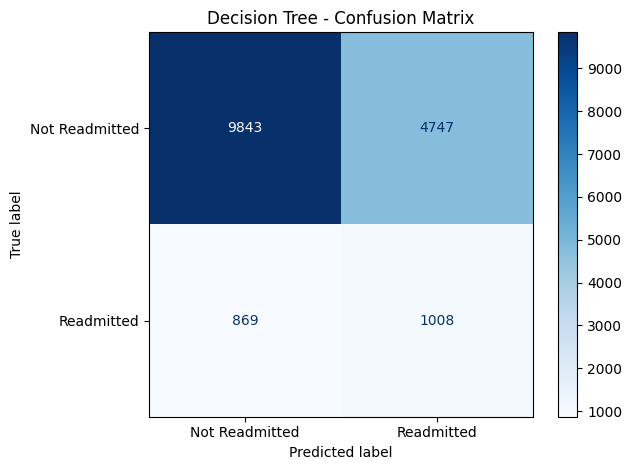

In [10]:

# ============================================
# DAY 7 - PART 5: CONFUSION MATRIX
# ============================================

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Calculate confusion matrix
dt_cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=[0, 1]
)

print("========== CONFUSION MATRIX ==========")
print(dt_cm)

TN = dt_cm[0, 0]
FP = dt_cm[0, 1]
FN = dt_cm[1, 0]
TP = dt_cm[1, 1]

print("\nTN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)

# Classification report
print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_val,
        y_val_pred,
        labels=[0, 1],
        target_names=["Not Readmitted", "Readmitted"],
        zero_division=0
    )
)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=dt_cm,
    display_labels=["Not Readmitted", "Readmitted"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()


In [11]:

# ============================================
# DAY 7 - PART 6: SAVE MODEL AND RESULTS
# ============================================

import json

# Create directories
models_path = os.path.join(PROJECT_PATH, "models")
results_path = os.path.join(PROJECT_PATH, "results")

os.makedirs(models_path, exist_ok=True)
os.makedirs(results_path, exist_ok=True)

# Save trained model
dt_model_path = os.path.join(
    models_path,
    "decision_tree_baseline.joblib"
)

joblib.dump(
    decision_tree_model,
    dt_model_path
)

# Save metrics
dt_metrics_path = os.path.join(
    results_path,
    "day7_decision_tree_metrics.json"
)

with open(dt_metrics_path, "w") as file:
    json.dump(decision_tree_metrics, file, indent=4)

# Save validation predictions
dt_predictions = pd.DataFrame({
    "actual": y_val,
    "predicted": y_val_pred,
    "readmission_probability": y_val_prob
})

dt_predictions_path = os.path.join(
    results_path,
    "day7_validation_predictions.csv"
)

dt_predictions.to_csv(
    dt_predictions_path,
    index=False
)

# Save confusion matrix
dt_cm_path = os.path.join(
    results_path,
    "day7_confusion_matrix.csv"
)

pd.DataFrame(
    dt_cm,
    index=["Actual_0", "Actual_1"],
    columns=["Predicted_0", "Predicted_1"]
).to_csv(dt_cm_path)

# Verify files
print("========== SAVED FILES ==========")

for path in [
    dt_model_path,
    dt_metrics_path,
    dt_predictions_path,
    dt_cm_path
]:
    print(os.path.basename(path), ":", os.path.exists(path))


========== SAVED FILES ==========
decision_tree_baseline.joblib : True
day7_decision_tree_metrics.json : True
day7_validation_predictions.csv : True
day7_confusion_matrix.csv : True


In [12]:

# ============================================
# DAY 7 - PART 7: MODEL COMPARISON
# ============================================

lr_metrics_path = os.path.join(
    PROJECT_PATH,
    "results",
    "day6_logistic_regression_metrics.json"
)

if not os.path.exists(lr_metrics_path):
    raise FileNotFoundError(
        "Day 6 Logistic Regression metrics file not found."
    )

with open(lr_metrics_path, "r") as file:
    lr_metrics = json.load(file)

# Display original Day 6 metrics structure
print("Day 6 metrics keys:")
print(list(lr_metrics.keys()))

print("\nDay 6 metrics content:")
print(json.dumps(lr_metrics, indent=4))


Day 6 metrics keys:
['logistic_regression', 'dummy_classifier', 'confusion_matrix', 'threshold', 'evaluation_dataset']

Day 6 metrics content:
{
    "logistic_regression": {
        "Model": "Logistic Regression",
        "Accuracy": 0.6540960709297383,
        "Precision": 0.1765204133491445,
        "Recall": 0.5551411827384124,
        "F1_Score": 0.267866323907455,
        "Balanced_Accuracy": 0.6109838881478217,
        "ROC_AUC": 0.6595766800083109,
        "Average_Precision": 0.22348215272377925
    },
    "dummy_classifier": {
        "Model": "Dummy Classifier",
        "Accuracy": 0.8860144531487217,
        "Precision": 0.0,
        "Recall": 0.0,
        "F1_Score": 0.0,
        "Balanced_Accuracy": 0.5,
        "ROC_AUC": 0.5,
        "Average_Precision": 0.11398554685127832
    },
    "confusion_matrix": [
        [
            9729,
            4861
        ],
        [
            835,
            1042
        ]
    ],
    "threshold": 0.5,
    "evaluation_dataset": "V

In [13]:

# ============================================
# DAY 7 - PART 7: FINAL MODEL COMPARISON
# ============================================

# Extract Logistic Regression metrics
lr_results = lr_metrics["logistic_regression"]

# Decision Tree metrics are already available
dt_results = decision_tree_metrics

# Metrics to compare
metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1_Score",
    "Balanced_Accuracy",
    "ROC_AUC",
    "Average_Precision"
]

# Create comparison table
comparison_data = []

for metric in metric_names:

    comparison_data.append({
        "Metric": metric,
        "Logistic Regression": lr_results[metric],
        "Decision Tree": dt_results[metric]
    })

comparison_df = pd.DataFrame(comparison_data)

print("========== MODEL COMPARISON ==========")

print(
    comparison_df.to_string(
        index=False,
        formatters={
            "Logistic Regression": "{:.4f}".format,
            "Decision Tree": "{:.4f}".format
        }
    )
)

# Save comparison
comparison_path = os.path.join(
    results_path,
    "day7_model_comparison.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)

print("\nComparison saved:", os.path.exists(comparison_path))


========== MODEL COMPARISON ==========
           Metric Logistic Regression Decision Tree
         Accuracy              0.6541        0.6590
        Precision              0.1765        0.1752
           Recall              0.5551        0.5370
         F1_Score              0.2679        0.2642
Balanced_Accuracy              0.6110        0.6058
          ROC_AUC              0.6596        0.6455
Average_Precision              0.2235        0.2074

Comparison saved: True


In [17]:
import os

PROJECT_PATH = "/content/drive/MyDrive/Machine learing project"

print("Project folder exists:", os.path.exists(PROJECT_PATH))

if os.path.exists(PROJECT_PATH):
    for root, dirs, files in os.walk(PROJECT_PATH):
        if ".git" in dirs:
            print("Git repository found:", root)
            dirs.remove(".git")

Project folder exists: True


In [18]:
import os

PROJECT_PATH = "/content/drive/MyDrive/Machine learing project"

git_found = False

for root, dirs, files in os.walk(PROJECT_PATH):
    if ".git" in dirs:
        print("Git repository found:", root)
        git_found = True
        dirs.remove(".git")

if not git_found:
    print("No Git repository found in Google Drive.")

No Git repository found in Google Drive.


In [19]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [20]:
import os
import subprocess

REPO_URL = "https://github.com/PredictiveHealth-AI/hospital-patient-readmission-prediction.git"

REPO_PATH = "/content/hospital-patient-readmission-prediction"

result = subprocess.run(
    [
        "git", "clone",
        "--branch", "Demo-Main",
        REPO_URL,
        REPO_PATH
    ],
    capture_output=True,
    text=True
)

print("STDOUT:", result.stdout)
print("STDERR:", result.stderr)
print("Return code:", result.returncode)

STDOUT: 
STDERR: Cloning into '/content/hospital-patient-readmission-prediction'...

Return code: 0


In [21]:
os.chdir(REPO_PATH)

result = subprocess.run(
    ["git", "status", "-sb"],
    capture_output=True,
    text=True
)

print(result.stdout)

## Demo-Main...origin/Demo-Main



In [22]:
import subprocess
import os

os.chdir("/content/hospital-patient-readmission-prediction")

result = subprocess.run(
    [
        "git", "switch", "-c",
        "feature/day-7-decision-tree"
    ],
    capture_output=True,
    text=True
)

print("STDOUT:", result.stdout)
print("STDERR:", result.stderr)
print("Return code:", result.returncode)


STDOUT: 
STDERR: Switched to a new branch 'feature/day-7-decision-tree'

Return code: 0


In [23]:
result = subprocess.run(
    ["git", "status", "-sb"],
    capture_output=True,
    text=True
)

print(result.stdout)


## feature/day-7-decision-tree



In [24]:
import glob

notebooks = glob.glob("/content/drive/MyDrive/**/*.ipynb", recursive=True)

for notebook in notebooks:
    if "Group8_Readmission_Prediction" in notebook:
        print(notebook)

/content/drive/MyDrive/Colab Notebooks/Group8_Readmission_Prediction.ipynb
